# Граф переводов: три модели поиска счетов-дропов

Блокнот к разделу 3 ВКР «Платёжный помощник». Это тот же расчёт, что выполняет лаборатория (`graph/prepare.py` и `graph/train.py`), только разложенный по шагам: ячейку можно запустить, посмотреть результат, поменять параметр и запустить снова.

**Задача.** Есть 5 млн банковских переводов. Нужно по истории переводов найти счета, на которые приходят «грязные» деньги (в России такие счета называют дропами). Для каждого счёта-получателя модель выдаёт оценку риска от 0 до 1.

**План**

| Часть | Что делаем |
|---|---|
| 0. Подготовка | библиотеки, общие настройки, загрузка датасета |
| 1. Датасет | смотрим столбцы и качество данных, строим граф счетов, считаем признаки, делим счета на выборки |
| 2. Модель 1 — логистическая регрессия | смотрит только на признаки самого счёта |
| 3. Модель 2 — градиентный бустинг | признаки счёта + средние признаки его соседей по графу |
| 4. Модель 3 — GraphSAGE | графовая нейросеть: сама учится, что брать у соседей |
| 5. Сравнение | все модели на одних и тех же тестовых счетах |

**Как запускать.** Ячейки выполняются сверху вниз: `Shift + Enter` запускает текущую ячейку. Можно и сразу все: «Среда выполнения → Выполнить все».
- Ячейки с полями справа (они помечены ✎) — это настройки. Поменяйте значение и перезапустите эту ячейку **и все ячейки ниже неё в том же разделе**.
- Для GraphSAGE лучше включить GPU: «Среда выполнения → Сменить среду выполнения → T4 GPU». Без GPU блокнот тоже работает, просто обучение сети займёт 15–30 минут вместо пары минут.

---
## 0. Подготовка

In [1]:
# @title Библиотеки
# Всё уже установлено в Google Colab, ничего ставить не нужно.
import time, os, urllib.request, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve

warnings.filterwarnings("ignore", category=UserWarning)  # бета-предупреждения PyTorch о разреженных матрицах
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
BLUE, ORANGE, GREEN, RED, GREY = "#2f5d8a", "#d9822b", "#3a8a5c", "#b5473a", "#8a8f98"

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Устройство для нейросети:", DEVICE)

Устройство для нейросети: cpu


In [2]:
# @title ✎ Общие настройки
# SEED — «зерно» случайности. От него зависит, какие счета попадут в обучение, проверку и тест,
# и с каких случайных весов начнёт нейросеть. При одном и том же SEED результат повторяется.
SEED = 42  # @param {type:"integer"}

np.random.seed(SEED)
torch.manual_seed(SEED)
print("SEED =", SEED)

SEED = 42


### Загрузка датасета

Датасет — **IBM AMLworld, вариант HI-Small** (Altman et al., NeurIPS 2023). Это синтетические переводы: IBM смоделировала мир из банков, людей и компаний, а внутри него — схемы отмывания денег. Поэтому про каждый перевод точно известно, «грязный» он или нет. На реальных банковских данных такой разметки нет, а сами данные закрыты.

Файл весит 454 МБ. Ячейка скачивает его в Colab (1–3 минуты). Если файл уже скачан, повторно он не качается.

In [3]:
# @title Скачать HI-Small_Trans.csv
URL = "https://huggingface.co/datasets/bbfizp/AMLSim-HI-Small/resolve/main/HI-Small_Trans.csv"
CSV_PATH = "HI-Small_Trans.csv"

if not os.path.exists(CSV_PATH):
    t0 = time.time()
    print("Скачиваю…")
    urllib.request.urlretrieve(URL, CSV_PATH)
    print(f"Готово за {time.time() - t0:.0f} с")
print(f"{CSV_PATH}: {os.path.getsize(CSV_PATH) / 2**20:.0f} МБ")

HI-Small_Trans.csv: 454 МБ


---
## 1. Датасет

### 1.1. Что лежит в файле

Одна строка — один перевод. Столбцов 11:

| Столбец | Что значит | Используем? |
|---|---|---|
| `Timestamp` | дата и время перевода (с точностью до минуты) | да: дни активности, скорость пересылки |
| `From Bank` | код банка отправителя | да: часть «адреса» счёта |
| `Account` | номер счёта отправителя | да |
| `To Bank` | код банка получателя | да |
| `Account.1` | номер счёта получателя (в файле второй столбец тоже называется `Account`, pandas переименовывает его) | да |
| `Amount Received` | сколько пришло получателю | да: суммы |
| `Receiving Currency` | валюта поступления | да: перевод в доллары, число валют |
| `Amount Paid` | сколько списали у отправителя | нет: равно `Amount Received`, кроме 72 тыс. переводов с обменом валюты |
| `Payment Currency` | валюта списания | нет |
| `Payment Format` | способ: ACH, Wire, Cheque, Credit Card, Cash, Bitcoin, Reinvestment | да: доли способов |
| `Is Laundering` | **1 — перевод часть схемы отмывания**, 0 — обычный | только как правильный ответ |

`Is Laundering` — это и есть то, что модели учатся угадывать. В расчёт признаков он **не попадает**, иначе модель «подсмотрела» бы ответ.

In [4]:
# @title Читаем CSV (около минуты)
t0 = time.time()
df = pd.read_csv(CSV_PATH, dtype={"From Bank": str, "Account": str, "To Bank": str, "Account.1": str})
print(f"Прочитано за {time.time() - t0:.0f} с: {len(df):_} строк, {df.shape[1]} столбцов".replace("_", " "))
df.head(8)

Прочитано за 4 с: 5 078 345 строк, 11 столбцов


,Timestamp,From Bank,Account,To Bank,Account.1,Amount Received,Receiving Currency,Amount Paid,Payment Currency,Payment Format,Is Laundering
0,2022/09/01 00:20,010,8000EBD30,010,8000EBD30,3697.34,US Dollar,3697.34,US Dollar,Reinvestment,0
1,2022/09/01 00:20,03208,8000F4580,001,8000F5340,0.01,US Dollar,0.01,US Dollar,Cheque,0
2,2022/09/01 00:00,03209,8000F4670,03209,8000F4670,14675.57,US Dollar,14675.57,US Dollar,Reinvestment,0
3,2022/09/01 00:02,012,8000F5030,012,8000F5030,2806.97,US Dollar,2806.97,US Dollar,Reinvestment,0
4,2022/09/01 00:06,010,8000F5200,010,8000F5200,36682.97,US Dollar,36682.97,US Dollar,Reinvestment,0
5,2022/09/01 00:03,001,8000F5AD0,001,8000F5AD0,6162.44,US Dollar,6162.44,US Dollar,Reinvestment,0
6,2022/09/01 00:08,001,8000EBAC0,001,8000EBAC0,14.26,US Dollar,14.26,US Dollar,Reinvestment,0
7,2022/09/01 00:16,001,8000EC1E0,001,8000EC1E0,11.86,US Dollar,11.86,US Dollar,Reinvestment,0


In [5]:
# @title Типы столбцов и объём в памяти
df.info(memory_usage="deep")

<class 'pandas.DataFrame'>
RangeIndex: 5078345 entries, 0 to 5078344
Data columns (total 11 columns):
 #   Column              Dtype  
---  ------              -----  
 0   Timestamp           str    
 1   From Bank           str    
 2   Account             str    
 3   To Bank             str    
 4   Account.1           str    
 5   Amount Received     float64
 6   Receiving Currency  str    
 7   Amount Paid         float64
 8   Payment Currency    str    
 9   Payment Format      str    
 10  Is Laundering       int64  
dtypes: float64(2), int64(1), str(8)
memory usage: 2.3 GB


### 1.2. Проверка качества

Прежде чем что-то обучать, проверяем данные: нет ли пропусков, повторов, странных значений.

In [6]:
# @title Пропуски, дубликаты, переводы самому себе
ts = pd.to_datetime(df["Timestamp"], format="%Y/%m/%d %H:%M")
src_key = df["From Bank"] + ":" + df["Account"]      # счёт = банк + номер
dst_key = df["To Bank"] + ":" + df["Account.1"]
ill = df["Is Laundering"] == 1
self_tx = src_key == dst_key

checks = pd.Series({
    "строк": len(df),
    "пустых ячеек (во всех столбцах)": int(df.isna().sum().sum()),
    "полностью одинаковых строк": int(df.duplicated().sum()),
    "переводов самому себе": int(self_tx.sum()),
    "  из них «отмывание»": int((self_tx & ill).sum()),
    "переводов с обменом валюты": int((df["Receiving Currency"] != df["Payment Currency"]).sum()),
    "переводов «отмывание»": int(ill.sum()),
    "доля «отмывания», %": round(ill.mean() * 100, 3),
    "разных банков": pd.concat([df["From Bank"], df["To Bank"]]).nunique(),
    "разных счетов": pd.concat([src_key, dst_key]).nunique(),
}, dtype=object).to_frame("значение")
print("Период:", ts.min(), "—", ts.max())
checks

Период: 2022-09-01 00:00:00 — 2022-09-18 16:18:00


,значение
строк,5078345
пустых ячеек (во всех столбцах),0
полностью одинаковых строк,9
переводов самому себе,591212
из них «отмывание»,11
переводов с обменом валюты,72170
переводов «отмывание»,5177
"доля «отмывания», %",0.102
разных банков,30528
разных счетов,515088


**Что из этого следует для подготовки:**

- **Пропусков нет** — заполнять ничего не надо.
- **Одинаковых строк 9** из 5 млн. Это могут быть и настоящие повторные платежи (та же сумма в ту же минуту), поэтому их не удаляем: на признаки они почти не влияют.
- **Переводы самому себе** (около 590 тыс., в основном `Reinvestment`) не связывают два разных счёта, поэтому в граф их не берём.
- **Суммы в 15 валютах**, включая биткоин. Чтобы их можно было сравнивать, переводим всё в доллары по примерным курсам.
- **Классы сильно несбалансированы**: «отмывание» — около 0,1 % переводов. Из-за этого метрика «доля верных ответов» бесполезна (модель «всегда нет» даст 99,9 %). Ниже используем PR-AUC.

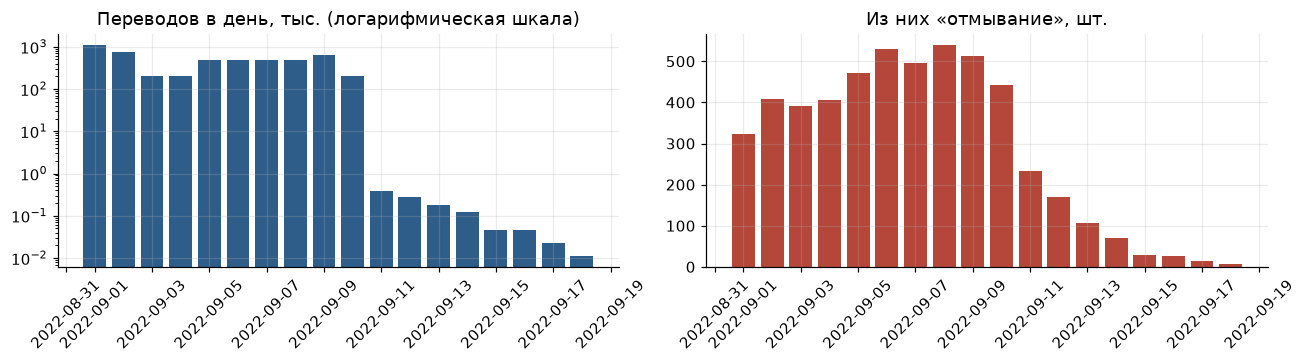

С 11 сентября переводов почти нет (сотни в день), и больше половины из них помечены как «отмывание».


In [7]:
# @title График: переводы по дням
day = ts.dt.normalize()
by_day = pd.DataFrame({"всего": day.value_counts().sort_index(),
                       "отмывание": day[ill].value_counts().sort_index()}).fillna(0)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
ax[0].bar(by_day.index, by_day["всего"] / 1000, color=BLUE)
ax[0].set_yscale("log"); ax[0].set_title("Переводов в день, тыс. (логарифмическая шкала)")
ax[1].bar(by_day.index, by_day["отмывание"], color=RED)
ax[1].set_title("Из них «отмывание», шт.")
for a in ax:
    a.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()
print("С 11 сентября переводов почти нет (сотни в день), и больше половины из них помечены как «отмывание».")

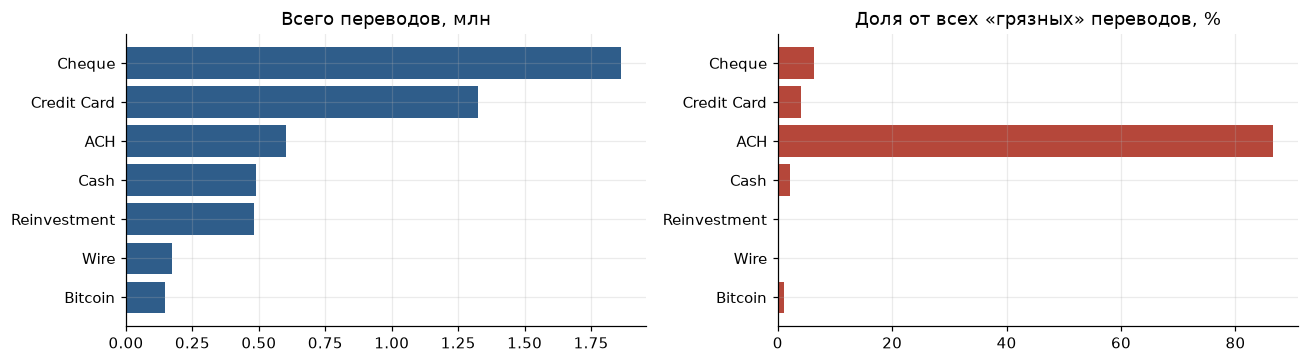

,переводов,отмывание,"доля отмывания, %","доля от всего отмывания, %"
Payment Format,,,,
Cheque,1864331,324,0.017,6.3
Credit Card,1323324,206,0.016,4.0
ACH,600797,4483,0.746,86.6
Cash,490891,108,0.022,2.1
Reinvestment,481056,0,0.000,0.0
Wire,171855,0,0.000,0.0
Bitcoin,146091,56,0.038,1.1


In [8]:
# @title График: способ оплаты — где прячется отмывание
fm = pd.DataFrame({"переводов": df["Payment Format"].value_counts(),
                   "отмывание": df.loc[ill, "Payment Format"].value_counts()}).fillna(0).astype(int)
fm["доля отмывания, %"] = (fm["отмывание"] / fm["переводов"] * 100).round(3)
fm["доля от всего отмывания, %"] = (fm["отмывание"] / fm["отмывание"].sum() * 100).round(1)
fm = fm.sort_values("переводов", ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
ax[0].barh(fm.index, fm["переводов"] / 1e6, color=BLUE); ax[0].invert_yaxis()
ax[0].set_title("Всего переводов, млн")
ax[1].barh(fm.index, fm["доля от всего отмывания, %"], color=RED); ax[1].invert_yaxis()
ax[1].set_title("Доля от всех «грязных» переводов, %")
plt.tight_layout(); plt.show()
fm

### 1.3. Строим граф счетов

Дальше работаем не с переводами, а со **счетами**:

- **вершина** графа — счёт (банк + номер);
- **ребро A → B** — «со счёта A хотя бы раз переводили на счёт B».

Каждому счёту даём номер от 0 до N−1 (`pd.factorize`), чтобы дальше работать с массивами чисел, а не со строками.

In [9]:
# @title Номера счетов и рёбра
USD_RATE = {  # примерные курсы к доллару (2022 г.)
    "US Dollar": 1.0, "Euro": 1.0, "UK Pound": 1.17, "Swiss Franc": 1.03, "Canadian Dollar": 0.75,
    "Australian Dollar": 0.68, "Yuan": 0.145, "Yen": 0.0071, "Rupee": 0.0125, "Ruble": 0.017,
    "Shekel": 0.29, "Mexican Peso": 0.05, "Brazil Real": 0.19, "Saudi Riyal": 0.27, "Bitcoin": 20000.0,
}
FORMATS = ["ACH", "Bitcoin", "Cash", "Cheque", "Credit Card", "Reinvestment", "Wire"]

total_rows = len(df)
codes, keys = pd.factorize(pd.concat([src_key, dst_key], ignore_index=True))
keys = np.asarray(keys, dtype=str)
N = len(keys)
src = codes[:total_rows].astype(np.int64)   # номер счёта-отправителя для каждого перевода
dst = codes[total_rows:].astype(np.int64)   # номер счёта-получателя

minutes = ((ts - ts.min()).dt.total_seconds() // 60).astype(np.int64).to_numpy()  # минуты от начала
usd = df["Amount Received"].to_numpy() * df["Receiving Currency"].map(USD_RATE).astype(float).to_numpy()
fmt = df["Payment Format"].map({f: i for i, f in enumerate(FORMATS)}).astype(int).to_numpy()
cur = df["Receiving Currency"].astype("category").cat.codes.to_numpy()
illicit = df["Is Laundering"].to_numpy().astype(bool)

# Убираем переводы самому себе
keep = src != dst
src, dst, minutes, usd, fmt, cur, illicit = (a[keep] for a in (src, dst, minutes, usd, fmt, cur, illicit))

edges = np.unique(np.stack([src, dst], 1), axis=0)   # уникальные пары A→B
print(f"Счетов (вершин): {N:,}\nПереводов между разными счетами: {len(src):,}\nРёбер (уникальных пар A→B): {len(edges):,}".replace(",", " "))

Счетов (вершин): 515 088
Переводов между разными счетами: 4 487 133
Рёбер (уникальных пар A→B): 647 939


### 1.4. Признаки счёта

Для каждого счёта считаем 17 чисел — по ним модели и будут судить о счёте. Идея признаков — описать поведение «транзитного» счёта: на него приходит много денег от разных людей, и почти сразу всё уходит дальше.

| № | Признак | Как считается |
|---|---|---|
| 0 | входящих переводов | сколько переводов пришло на счёт |
| 1 | исходящих переводов | сколько ушло со счёта |
| 2 | сумма входящих, $ | всё, что пришло, в долларах |
| 3 | сумма исходящих, $ | всё, что ушло |
| 4 | разных отправителей | от скольких разных счетов приходили деньги |
| 5 | разных получателей | на сколько разных счетов отправлял |
| 6 | доля пересланного дальше | сумма исходящих / сумма входящих (не больше 5) |
| 7 | пересылка в течение суток | доля исходящих переводов, сделанных в первые 24 ч после первого поступления |
| 8 | дней активности | от первого до последнего перевода счёта |
| 9 | разных валют на входе | сколько валют приходило |
| 10–16 | доля входящих по способу | доля входящих переводов через ACH, Bitcoin, Cash, Cheque, Credit Card, Reinvestment, Wire |

In [10]:
# @title Считаем 17 признаков
in_cnt  = np.bincount(dst, minlength=N)                      # 0
out_cnt = np.bincount(src, minlength=N)                      # 1
in_sum  = np.bincount(dst, weights=usd, minlength=N)         # 2
out_sum = np.bincount(src, weights=usd, minlength=N)         # 3
uniq_senders   = np.bincount(edges[:, 1], minlength=N)       # 4
uniq_receivers = np.bincount(edges[:, 0], minlength=N)       # 5
pass_ratio = np.where(in_sum > 0, np.minimum(out_sum / np.maximum(in_sum, 1e-9), 5.0), 0.0)  # 6

# 7: время первого поступления → какая доля исходящих сделана в течение суток после него
first_in = np.full(N, np.iinfo(np.int64).max)
np.minimum.at(first_in, dst, minutes)
after = minutes - first_in[src]
quick = (after >= 0) & (after <= 24 * 60)
quick_share = np.where(out_cnt > 0, np.bincount(src, weights=quick, minlength=N) / np.maximum(out_cnt, 1), 0.0)

# 8: дни активности
t_min = np.full(N, np.iinfo(np.int64).max); t_max = np.zeros(N, dtype=np.int64)
np.minimum.at(t_min, src, minutes); np.minimum.at(t_min, dst, minutes)
np.maximum.at(t_max, src, minutes); np.maximum.at(t_max, dst, minutes)
days = np.where(t_max >= t_min, (t_max - t_min) / (24 * 60), 0.0)

# 9: разных валют на входе
cur_pairs = np.unique(np.stack([dst, cur], 1), axis=0)
n_cur = np.bincount(cur_pairs[:, 0], minlength=N)

# 10–16: доли способов оплаты среди входящих
fmt_share = np.zeros((N, len(FORMATS)))
np.add.at(fmt_share, (dst, fmt), 1)
fmt_share = fmt_share / np.maximum(in_cnt, 1)[:, None]

FEATURE_NAMES = ["входящих переводов", "исходящих переводов", "сумма входящих, $", "сумма исходящих, $",
                 "разных отправителей", "разных получателей", "доля пересланного дальше",
                 "пересылка в течение суток", "дней активности", "разных валют на входе"] + \
                ["доля входящих: " + f for f in FORMATS]

raw = np.column_stack([in_cnt, out_cnt, in_sum, out_sum, uniq_senders, uniq_receivers, pass_ratio,
                       quick_share, days, n_cur, fmt_share]).astype(np.float32)
print("Матрица признаков:", raw.shape, "(счетов × признаков)")
pd.DataFrame(raw[:5], columns=FEATURE_NAMES, index=keys[:5]).round(2)

Матрица признаков: (515088, 17) (счетов × признаков)


,входящих переводов,исходящих переводов,"сумма входящих, $","сумма исходящих, $",разных отправителей,разных получателей,доля пересланного дальше,пересылка в течение суток,дней активности,разных валют на входе,доля входящих: ACH,доля входящих: Bitcoin,доля входящих: Cash,доля входящих: Cheque,доля входящих: Credit Card,доля входящих: Reinvestment,доля входящих: Wire
010:8000EBD30,13.0,1.0,924.989990,1.466600e+02,12.0,1.0,0.16,0.00,8.00,1.0,0.00,0.0,0.0,0.15,0.85,0.0,0.0
03208:8000F4580,0.0,3.0,0.000000,1.440670e+03,0.0,2.0,0.00,0.00,8.42,0.0,0.00,0.0,0.0,0.00,0.00,0.0,0.0
03209:8000F4670,0.0,0.0,0.000000,0.000000e+00,0.0,0.0,0.00,0.00,0.00,0.0,0.00,0.0,0.0,0.00,0.00,0.0,0.0
012:8000F5030,19.0,1.0,13055.700195,1.171450e+05,19.0,1.0,5.00,0.00,9.02,1.0,0.42,0.0,0.0,0.00,0.58,0.0,0.0
010:8000F5200,10.0,29.0,740.210022,1.502425e+06,8.0,4.0,5.00,0.14,9.96,1.0,0.00,0.0,0.0,0.00,1.00,0.0,0.0


### 1.5. Правильный ответ (метка)

**Метка счёта = 1**, если на него хотя бы раз пришёл перевод с `Is Laundering = 1`. Иначе 0.

Оцениваем только **счета-получатели** (у кого был хотя бы один входящий перевод): у счёта, на который никогда ничего не приходило, «принимать грязные деньги» не получится.

Счетов-получателей: 284 394
Из них дропов (метка 1): 3 984 — 1.40 %


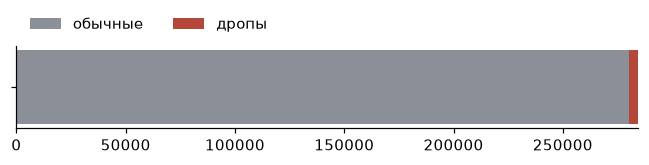

In [11]:
# @title Метки и баланс классов
y = np.zeros(N, dtype=np.int64)
y[np.unique(dst[illicit])] = 1
recipients = in_cnt > 0

n_rec, n_drop = int(recipients.sum()), int(y[recipients].sum())
print(f"Счетов-получателей: {n_rec:,}\nИз них дропов (метка 1): {n_drop:,} — {n_drop / n_rec * 100:.2f} %".replace(",", " "))

fig, ax = plt.subplots(figsize=(6, 1.6))
ax.barh([""], [n_rec - n_drop], color=GREY, label="обычные")
ax.barh([""], [n_drop], left=[n_rec - n_drop], color=RED, label="дропы")
ax.set_xlim(0, n_rec); ax.legend(loc="lower left", ncol=2, frameon=False, bbox_to_anchor=(0, 1))
ax.grid(False); plt.tight_layout(); plt.show()

In [12]:
# @title Чем дроп отличается от обычного счёта (медианы признаков)
cmp = pd.DataFrame({
    "обычный счёт": np.median(raw[recipients & (y == 0)], 0),
    "дроп": np.median(raw[recipients & (y == 1)], 0),
}, index=FEATURE_NAMES).round(3)
cmp

,обычный счёт,дроп
входящих переводов,16.000000,14.000000
исходящих переводов,1.000000,2.000000
"сумма входящих, $",26530.031250,26833.876953
"сумма исходящих, $",2217.763916,7831.850098
разных отправителей,2.000000,3.000000
разных получателей,1.000000,1.000000
доля пересланного дальше,0.042000,0.238000
пересылка в течение суток,0.000000,0.000000
дней активности,8.653000,8.672000
разных валют на входе,1.000000,1.000000


### 1.6. Масштабирование признаков

Признаки различаются на порядки: число переводов — единицы, сумма — миллионы долларов. Логистической регрессии и нейросети так неудобно: признак с большими числами «перекрикивает» остальные. Поэтому делаем два шага:

1. **Логарифм** `log(1 + x)` для счётчиков, сумм и дней (признаки 0, 1, 2, 3, 4, 5, 8) — сжимает огромные значения;
2. **Стандартизация**: из каждого признака вычитаем среднее и делим на разброс. После этого у всех признаков среднее 0 и разброс 1.

Бустингу это не нужно (деревья смотрят только на порядок значений), но для единообразия все модели получают одну и ту же матрицу `x`.

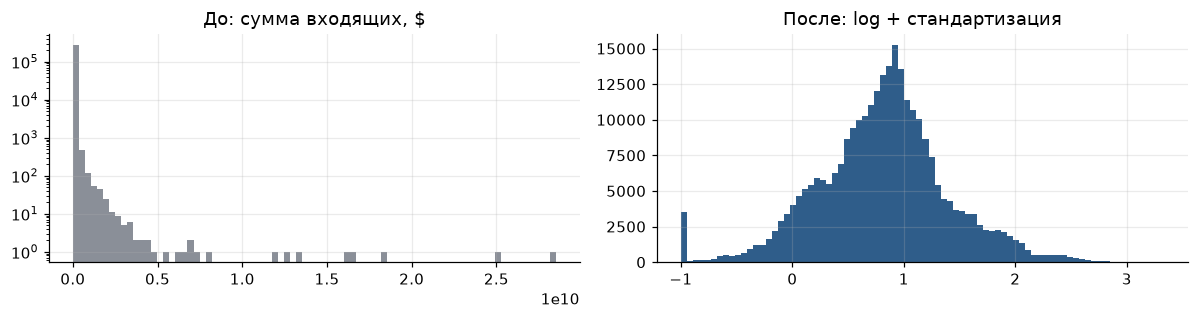

In [13]:
# @title Логарифм + стандартизация
x = raw.copy()
LOG_COLS = (0, 1, 2, 3, 4, 5, 8)
for j in LOG_COLS:
    x[:, j] = np.log1p(x[:, j])
x = (x - x.mean(0)) / (x.std(0) + 1e-6)

j = 2  # «сумма входящих, $» — посмотрим, что стало
m = recipients
fig, ax = plt.subplots(1, 2, figsize=(11, 3))
ax[0].hist(raw[m, j], bins=80, color=GREY); ax[0].set_title("До: сумма входящих, $"); ax[0].set_yscale("log")
ax[1].hist(x[m, j], bins=80, color=BLUE); ax[1].set_title("После: log + стандартизация")
plt.tight_layout(); plt.show()

### 1.7. Делим счета: обучение / проверка / тест

Счета-получатели случайно делятся на три группы, причём доля дропов в каждой одинаковая (стратификация):

- **обучение, 70 %** — на них модель учится;
- **проверка, 15 %** — по ним выбираем порог решения и лучшую эпоху нейросети;
- **тест, 15 %** — на них считаем итоговые цифры. Модель этих счетов не видела.

Важно: делим **счета**, а граф остаётся целым. Модель видит связи тестового счёта с соседями (это обычные данные о переводах), но не видит его метку.

In [14]:
# @title Разбиение
def make_split(y, candidates, seed):
    """0 — не участвует, 1 — обучение, 2 — проверка, 3 — тест."""
    rng = np.random.default_rng(seed)
    split = np.zeros(len(y), dtype=np.int8)
    for cls in (0, 1):
        idx = np.where(candidates & (y == cls))[0]
        rng.shuffle(idx)
        a, b = int(len(idx) * 0.70), int(len(idx) * 0.85)
        split[idx[:a]], split[idx[a:b]], split[idx[b:]] = 1, 2, 3
    return split

split = make_split(y, recipients, SEED)
tr, va, te = split == 1, split == 2, split == 3
pd.DataFrame({"счетов": [tr.sum(), va.sum(), te.sum()], "дропов": [y[tr].sum(), y[va].sum(), y[te].sum()]},
             index=["обучение", "проверка", "тест"])

,счетов,дропов
обучение,199075,2788
проверка,42659,598
тест,42660,598


### 1.8. Как оцениваем модели

Модель выдаёт каждому счёту число — оценку риска. Чем выше, тем подозрительнее. Метрики:

- **PR-AUC** (главная) — площадь под кривой «точность — полнота». Если выстроить счета по убыванию оценки, PR-AUC показывает, насколько дропы собраны наверху списка. Случайное угадывание даёт PR-AUC ≈ доле дропов, то есть **≈ 0,014**. Идеальная модель — 1.
- **ROC-AUC** — вероятность, что случайный дроп получит оценку выше случайного обычного счёта. При редком классе она обманчиво высокая, поэтому только для справки.
- **Полнота при 1 % ложных тревог** — какую долю дропов поймаем, если готовы зря потревожить 1 % обычных счетов.
- **Точность в топ-100** — сколько дропов среди 100 самых подозрительных счетов.

Ещё считаем **решение на пороге**: порог выбираем на проверке (там, где лучший F1 — баланс точности и полноты), а потом применяем к тесту и считаем, сколько дропов поймано и сколько обычных счетов задето зря.

In [15]:
# @title Функции оценки
RESULTS = {}   # сюда складываем результаты всех моделей для сравнения в конце

def evaluate(y_true, s):
    neg = s[y_true == 0]
    top = np.argsort(-s)[:100]
    return {
        "PR-AUC": average_precision_score(y_true, s),
        "ROC-AUC": roc_auc_score(y_true, s),
        "полнота при 1% ложных": (s[y_true == 1] > np.quantile(neg, 0.99)).mean(),
        "точность топ-100": y_true[top].mean(),
    }

def decide(score):
    """Порог — лучший F1 на проверке; итог — на тесте."""
    p, r, t = precision_recall_curve(y[va], score[va])
    f1 = (2 * p * r / np.maximum(p + r, 1e-9))[:-1]
    thr = t[int(np.argmax(f1))]
    pred, yt = score[te] >= thr, y[te] == 1
    return {"порог": thr, "поймано дропов": int((pred & yt).sum()), "пропущено дропов": int((~pred & yt).sum()),
            "ложных тревог": int((pred & ~yt).sum()), "обычных без тревоги": int((~pred & ~yt).sum())}

def report(name, score):
    """Печатает метрики, кладёт в RESULTS и рисует кривую точность—полнота."""
    m, d = evaluate(y[te], score[te]), decide(score)
    RESULTS[name] = {"score": score, **m, **d}
    print(pd.Series(m).round(3).to_string()); print()
    print("Решение на пороге (тестовые счета):")
    print(pd.Series(d, dtype=object).to_string())
    p, r, _ = precision_recall_curve(y[te], score[te])
    plt.figure(figsize=(5, 3.4))
    plt.plot(r, p, color=BLUE)
    plt.axhline(y[te].mean(), color=GREY, ls="--", lw=1, label="случайное угадывание")
    plt.xlabel("полнота (доля пойманных дропов)"); plt.ylabel("точность")
    plt.title(f"{name}: PR-AUC = {m['PR-AUC']:.3f}"); plt.legend(frameon=False)
    plt.tight_layout(); plt.show()

### 1.9. Отправная точка: простое правило

Прежде чем обучать модели, проверим самое простое правило без обучения: **«чем больше разных отправителей, тем подозрительнее»** (признак 4). Любая модель должна быть заметно лучше этого.

PR-AUC                   0.033
ROC-AUC                  0.679
полнота при 1% ложных    0.059
точность топ-100         0.100

Решение на пороге (тестовые счета):
порог                    7.0
поймано дропов            52
пропущено дропов         546
ложных тревог            753
обычных без тревоги    41309


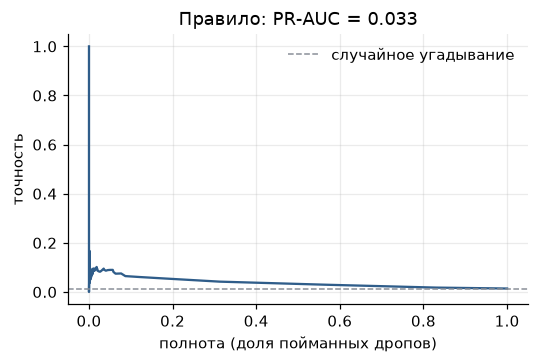

In [16]:
# @title Правило «много разных отправителей»
report("Правило", raw[:, 4].astype(float))

---
## 2. Модель 1 — логистическая регрессия

**Что делает.** Складывает 17 признаков счёта с весами и превращает сумму в вероятность:

$$p = \sigma(w_0 + w_1 x_1 + \dots + w_{17} x_{17}), \qquad \sigma(z) = \frac{1}{1 + e^{-z}}$$

Положительный вес — признак повышает риск, отрицательный — понижает. Обучение подбирает веса так, чтобы на обучающих счетах оценки как можно лучше совпали с метками.

**Что видит:** только 17 признаков самого счёта. О соседях не знает ничего.

In [17]:
# @title ✎ Параметры логистической регрессии
C = 1.0  # @param {type:"number"}
CLASS_WEIGHT = "balanced"  # @param ["balanced", "None"]
MAX_ITER = 500  # @param {type:"integer"}

# C — сила регуляризации наоборот: меньше C → веса сильнее прижимаются к нулю (модель проще).
# CLASS_WEIGHT="balanced" — ошибка на редком дропе «стоит» столько же, сколько на всех обычных вместе.
#   С "None" модель почти перестаёт замечать дропов: их всего 1,4 %.
# MAX_ITER — сколько шагов оптимизации разрешено (обычно хватает нескольких десятков).

In [18]:
# @title Обучение
t0 = time.time()
logreg = LogisticRegression(C=C, class_weight=None if CLASS_WEIGHT == "None" else CLASS_WEIGHT, max_iter=MAX_ITER)
logreg.fit(x[tr], y[tr])
print(f"Обучено за {time.time() - t0:.1f} с, шагов оптимизации: {logreg.n_iter_[0]}")
s_logreg = logreg.predict_proba(x)[:, 1]

Обучено за 0.4 с, шагов оптимизации: 34


PR-AUC                   0.054
ROC-AUC                  0.799
полнота при 1% ложных    0.059
точность топ-100         0.090

Решение на пороге (тестовые счета):
порог                  0.823731
поймано дропов              121
пропущено дропов            477
ложных тревог              1338
обычных без тревоги       40724


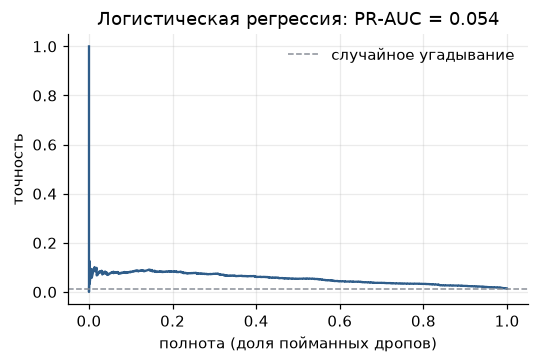

In [19]:
# @title Результат на тесте
report("Логистическая регрессия", s_logreg)

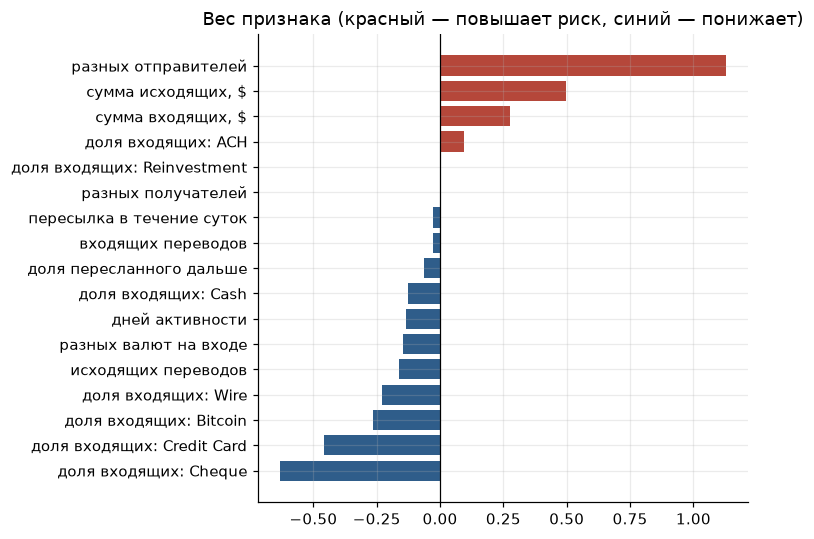

Признаки стандартизированы, поэтому веса можно сравнивать между собой. Свободный член w0 = -0.788


In [20]:
# @title Веса признаков: что модель считает подозрительным
w = pd.Series(logreg.coef_[0], index=FEATURE_NAMES).sort_values()
plt.figure(figsize=(7, 5))
plt.barh(w.index, w.values, color=[RED if v > 0 else BLUE for v in w.values])
plt.axvline(0, color="black", lw=0.8)
plt.title("Вес признака (красный — повышает риск, синий — понижает)")
plt.tight_layout(); plt.show()
print("Признаки стандартизированы, поэтому веса можно сравнивать между собой. Свободный член w0 =", round(logreg.intercept_[0], 3))

**Почему результат слабый.** Регрессия проводит одну «прямую» границу в пространстве признаков: каждый признак влияет на риск всегда в одну сторону и независимо от остальных. А у дропа важны сочетания («много входящих **и** быстро всё ушло») и то, **от кого** пришли деньги. Этого регрессия не видит.

---
## 3. Модель 2 — градиентный бустинг

**Что делает.** Строит много небольших деревьев решений одно за другим. Каждое следующее дерево исправляет ошибки уже построенных. Итоговая оценка — сумма ответов всех деревьев. Деревья умеют ловить сочетания признаков и пороги («если отправителей > 10 и пересылка за сутки > 0,8, то…»).

**Что видит:** 17 признаков самого счёта **плюс средние признаки его соседей** — всего 51 число:

- 17 — сам счёт;
- 17 — среднее по всем, **кто отправлял** деньги на этот счёт;
- 17 — среднее по всем, **кому** этот счёт отправлял.

Это «ручной» способ дать модели информацию о графе: мы сами решили, что брать у соседей (среднее), и сами посчитали.

In [21]:
# @title Средние признаки соседей
def mean_adjacency(edges, n, reverse):
    """Разреженная матрица A: (A @ x)[v] = среднее x по соседям v.
    reverse=False — соседи-отправители (кто слал на v), reverse=True — соседи-получатели (кому слал v)."""
    rows, cols = (edges[:, 1], edges[:, 0]) if not reverse else (edges[:, 0], edges[:, 1])
    deg = np.bincount(rows, minlength=n).astype(np.float32)
    vals = 1.0 / np.maximum(deg[rows], 1)
    idx = torch.tensor(np.stack([rows, cols]), dtype=torch.long)
    return torch.sparse_coo_tensor(idx, torch.tensor(vals), (n, n)).coalesce().to_sparse_csr()

A_in, A_out = mean_adjacency(edges, N, False), mean_adjacency(edges, N, True)
xt = torch.tensor(x)
with torch.no_grad():
    x_senders, x_receivers = (A_in @ xt).numpy(), (A_out @ xt).numpy()
x_graph = np.concatenate([x, x_senders, x_receivers], 1)
GB_NAMES = FEATURE_NAMES + ["отправители: " + f for f in FEATURE_NAMES] + ["получатели: " + f for f in FEATURE_NAMES]
print("Признаков для бустинга:", x_graph.shape[1])

Признаков для бустинга: 51


In [22]:
# @title ✎ Параметры бустинга
USE_NEIGHBORS = True  # @param {type:"boolean"}
GB_MAX_ITER = 300  # @param {type:"integer"}
GB_LEARNING_RATE = 0.1  # @param {type:"number"}
GB_MAX_LEAF_NODES = 31  # @param {type:"integer"}
GB_EARLY_STOPPING = True  # @param {type:"boolean"}

# USE_NEIGHBORS — давать ли признаки соседей. Выключите, чтобы увидеть, сколько дают соседи.
# GB_MAX_ITER — максимум деревьев.
# GB_LEARNING_RATE — насколько сильно каждое новое дерево поправляет предыдущие (меньше → осторожнее, нужно больше деревьев).
# GB_MAX_LEAF_NODES — размер одного дерева (листьев); больше → дерево ловит более сложные сочетания.
# GB_EARLY_STOPPING — бустинг откладывает 10 % обучающих счетов и останавливается, когда 10 деревьев подряд
#   не улучшили результат на них. Поэтому деревьев обычно меньше, чем GB_MAX_ITER.

In [23]:
# @title Обучение (около минуты)
X_GB = x_graph if USE_NEIGHBORS else x
t0 = time.time()
gb = HistGradientBoostingClassifier(max_iter=GB_MAX_ITER, learning_rate=GB_LEARNING_RATE,
                                    max_leaf_nodes=GB_MAX_LEAF_NODES, early_stopping=GB_EARLY_STOPPING,
                                    class_weight="balanced", random_state=SEED)
gb.fit(X_GB[tr], y[tr])
print(f"Обучено за {time.time() - t0:.0f} с, построено деревьев: {gb.n_iter_} из {GB_MAX_ITER}")
s_boost = gb.predict_proba(X_GB)[:, 1]

Обучено за 28 с, построено деревьев: 60 из 300


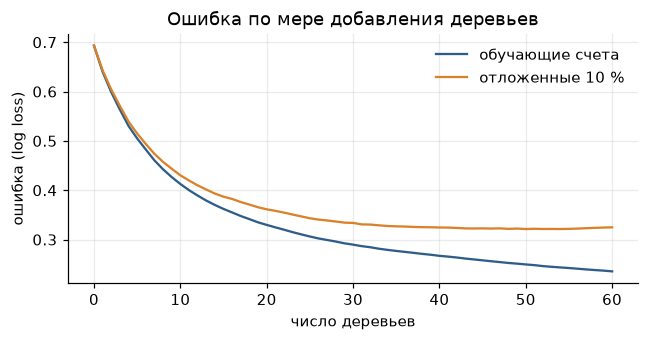

Когда оранжевая линия перестаёт снижаться, новые деревья только запоминают обучающие счета — бустинг останавливается.


In [24]:
# @title Как шло обучение
if GB_EARLY_STOPPING:
    plt.figure(figsize=(6, 3.2))
    plt.plot(-gb.train_score_, color=BLUE, label="обучающие счета")
    plt.plot(-gb.validation_score_, color=ORANGE, label="отложенные 10 %")
    plt.xlabel("число деревьев"); plt.ylabel("ошибка (log loss)")
    plt.title("Ошибка по мере добавления деревьев"); plt.legend(frameon=False)
    plt.tight_layout(); plt.show()
    print("Когда оранжевая линия перестаёт снижаться, новые деревья только запоминают обучающие счета — бустинг останавливается.")
else:
    print("Ранняя остановка выключена — кривой на отложенных счетах нет.")

PR-AUC                   0.338
ROC-AUC                  0.935
полнота при 1% ложных    0.318
точность топ-100         0.960

Решение на пороге (тестовые счета):
порог                  0.898173
поймано дропов              159
пропущено дропов            439
ложных тревог               186
обычных без тревоги       41876


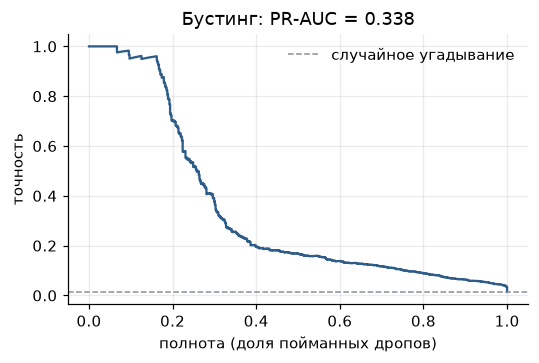

In [25]:
# @title Результат на тесте
report("Бустинг" + ("" if USE_NEIGHBORS else " без соседей"), s_boost)

**Какие признаки важны.** У деревьев нет весов, как у регрессии. Важность признака измеряем перестановкой: перемешиваем один признак между тестовыми счетами (связь с меткой ломается) и смотрим, насколько упал PR-AUC. Чем сильнее падение, тем больше модель на этот признак опирается.

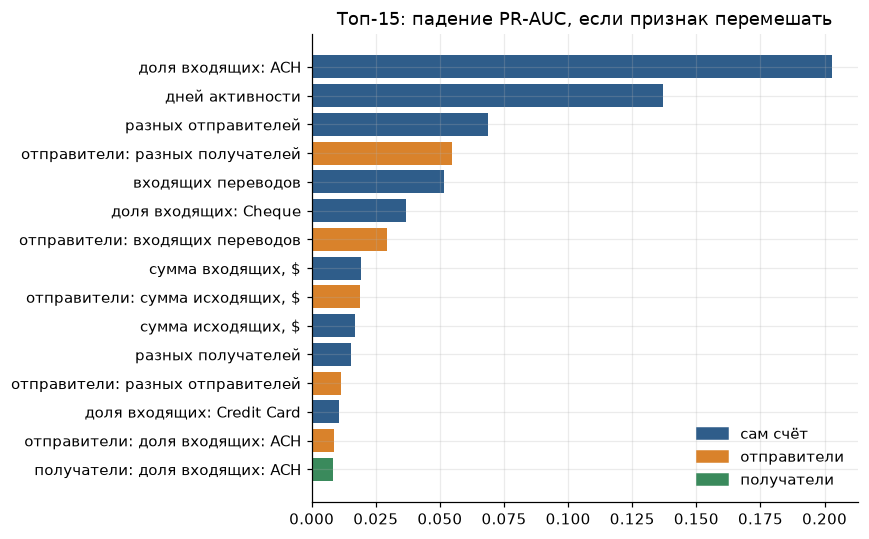

In [26]:
# @title Важность признаков (перестановка, около минуты)
rng = np.random.default_rng(SEED)
names = GB_NAMES if USE_NEIGHBORS else FEATURE_NAMES
Xte = X_GB[te]
base = average_precision_score(y[te], gb.predict_proba(Xte)[:, 1])
drop = []
for j in range(Xte.shape[1]):
    xp = Xte.copy()
    xp[:, j] = xp[rng.permutation(len(xp)), j]
    drop.append(base - average_precision_score(y[te], gb.predict_proba(xp)[:, 1]))
imp = pd.Series(drop, index=names).sort_values(ascending=False).head(15)[::-1]

color = [ORANGE if n.startswith("отправители") else GREEN if n.startswith("получатели") else BLUE for n in imp.index]
plt.figure(figsize=(8, 5))
plt.barh(imp.index, imp.values, color=color)
plt.title("Топ-15: падение PR-AUC, если признак перемешать")
from matplotlib.patches import Patch
plt.legend(handles=[Patch(color=BLUE, label="сам счёт"), Patch(color=ORANGE, label="отправители"),
                    Patch(color=GREEN, label="получатели")], frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

---
## 4. Модель 3 — GraphSAGE

**Идея.** Бустингу мы сами дали «средние по соседям». GraphSAGE (Hamilton et al., 2017) — нейросеть, которая **сама учится**, какую информацию собирать от соседей и как её смешивать со своей.

**Один слой** обновляет описание каждого счёта v:

$$h_v' = \mathrm{ReLU}\big(\,W_0\,h_v \;+\; W_{in}\cdot\text{среднее}(h_u : u \to v) \;+\; W_{out}\cdot\text{среднее}(h_u : v \to u)\,\big)$$

- $h_v$ — текущее описание счёта (вначале это его 17 признаков);
- $W_0$, $W_{in}$, $W_{out}$ — матрицы весов, которые подбираются при обучении: что взять от себя, от отправителей, от получателей;
- отправители и получатели учитываются раздельно, потому что направление денег важно.

**Два слоя подряд** — счёт «видит» соседей соседей: откуда пришли деньги к тем, кто прислал деньги ему. После слоёв линейная «голова» превращает описание в одну оценку риска.

**Обучение.** Каждая эпоха — один проход по всему графу: сеть считает оценки, сравниваются с метками **только обучающих** счетов, веса чуть поправляются (оптимизатор Adam). Каждые 5 эпох смотрим PR-AUC на проверке и запоминаем лучшее состояние сети.

In [27]:
# @title Устройство сети (код)
class SageLayer(nn.Module):
    """h' = W0·h + W_in·среднее(h отправителей) + W_out·среднее(h получателей)"""
    def __init__(self, d_in, d_out):
        super().__init__()
        self.self_lin = nn.Linear(d_in, d_out)
        self.in_lin = nn.Linear(d_in, d_out, bias=False)
        self.out_lin = nn.Linear(d_in, d_out, bias=False)

    def forward(self, h, a_in, a_out):
        return self.self_lin(h) + self.in_lin(a_in @ h) + self.out_lin(a_out @ h)


class GraphSAGE(nn.Module):
    def __init__(self, d_in, hidden, layers, dropout):
        super().__init__()
        dims = [d_in] + [hidden] * layers
        self.layers = nn.ModuleList(SageLayer(a, b) for a, b in zip(dims[:-1], dims[1:]))
        self.drop = nn.Dropout(dropout)
        self.head = nn.Linear(hidden, 1)     # описание счёта → одна оценка

    def forward(self, x, a_in, a_out):
        h = x
        for layer in self.layers:
            h = self.drop(torch.relu(layer(h, a_in, a_out)))
        return self.head(h).squeeze(-1)

In [28]:
# @title ✎ Параметры GraphSAGE
EPOCHS = 300  # @param {type:"integer"}
HIDDEN = 64  # @param {type:"integer"}
LAYERS = 2  # @param {type:"integer"}
LR = 0.02  # @param {type:"number"}
DROPOUT = 0.2  # @param {type:"number"}
WEIGHT_DECAY = 1e-5  # @param {type:"number"}

# EPOCHS — сколько проходов по графу. Лучшую эпоху выбираем по проверке, так что лишние эпохи не вредят, только тратят время.
# HIDDEN — длина описания счёта внутри сети (сколько чисел). Больше → сеть «умнее», но дольше и легче переобучается.
# LAYERS — сколько слоёв: 1 — только прямые соседи, 2 — соседи соседей, 3 — ещё дальше.
# LR — шаг обучения: насколько сильно поправлять веса за эпоху. Слишком большой — обучение скачет, слишком маленький — идёт медленно.
# DROPOUT — доля чисел, которые случайно «выключаются» при обучении; мешает сети запоминать обучающие счета.
# WEIGHT_DECAY — штраф за большие веса (то же, что регуляризация у регрессии).

In [29]:
# @title Обучение (GPU: пара минут, без GPU: 15–30 мин)
torch.manual_seed(SEED)
model = GraphSAGE(x.shape[1], HIDDEN, LAYERS, DROPOUT).to(DEVICE)
opt = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)

X_t = torch.tensor(x).to(DEVICE)
a_in, a_out = A_in.to(DEVICE), A_out.to(DEVICE)
y_t = torch.tensor(y, dtype=torch.float32).to(DEVICE)
tr_t = torch.tensor(tr).to(DEVICE)
va_idx = np.where(va)[0]
# Дропов мало, поэтому ошибку на дропе умножаем на (обычных / дропов) ≈ 70 — иначе сеть их проигнорирует.
pos_weight = torch.tensor((y[tr] == 0).sum() / max(1, (y[tr] == 1).sum()), dtype=torch.float32).to(DEVICE)
loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

best, best_state, curve = -1.0, None, []
t0 = time.time()
for epoch in range(1, EPOCHS + 1):
    model.train(); opt.zero_grad()
    logits = model(X_t, a_in, a_out)
    loss = loss_fn(logits[tr_t], y_t[tr_t])     # ошибка только по обучающим счетам
    loss.backward(); opt.step()
    if epoch % 5 == 0 or epoch == EPOCHS:
        model.eval()
        with torch.no_grad():
            sv = torch.sigmoid(model(X_t, a_in, a_out)).cpu().numpy()
        val_ap = average_precision_score(y[va_idx], sv[va_idx])
        curve.append((epoch, loss.item(), val_ap))
        if val_ap > best:
            best, best_epoch = val_ap, epoch
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        if epoch % 25 == 0 or epoch == EPOCHS:
            print(f"эпоха {epoch:4d}   ошибка {loss.item():.4f}   PR-AUC на проверке {val_ap:.3f}   ({time.time() - t0:.0f} с)")

model.load_state_dict(best_state); model.eval()
with torch.no_grad():
    s_sage = torch.sigmoid(model(X_t, a_in, a_out)).cpu().numpy()
print(f"\nЛучшая эпоха: {best_epoch} (PR-AUC на проверке {best:.3f}). Берём состояние сети с этой эпохи.")

эпоха   25   ошибка 0.9387   PR-AUC на проверке 0.080   (66 с)


эпоха   50   ошибка 0.7674   PR-AUC на проверке 0.123   (131 с)


эпоха   75   ошибка 0.6690   PR-AUC на проверке 0.170   (194 с)


эпоха  100   ошибка 0.5967   PR-AUC на проверке 0.223   (258 с)


эпоха  125   ошибка 0.5684   PR-AUC на проверке 0.251   (321 с)


эпоха  150   ошибка 0.5337   PR-AUC на проверке 0.290   (385 с)


... (3 outputs left out)

эпоха  250   ошибка 0.4969   PR-AUC на проверке 0.316   (643 с)


эпоха  275   ошибка 0.4761   PR-AUC на проверке 0.329   (707 с)


эпоха  300   ошибка 0.4536   PR-AUC на проверке 0.341   (772 с)



Лучшая эпоха: 300 (PR-AUC на проверке 0.341). Берём состояние сети с этой эпохи.


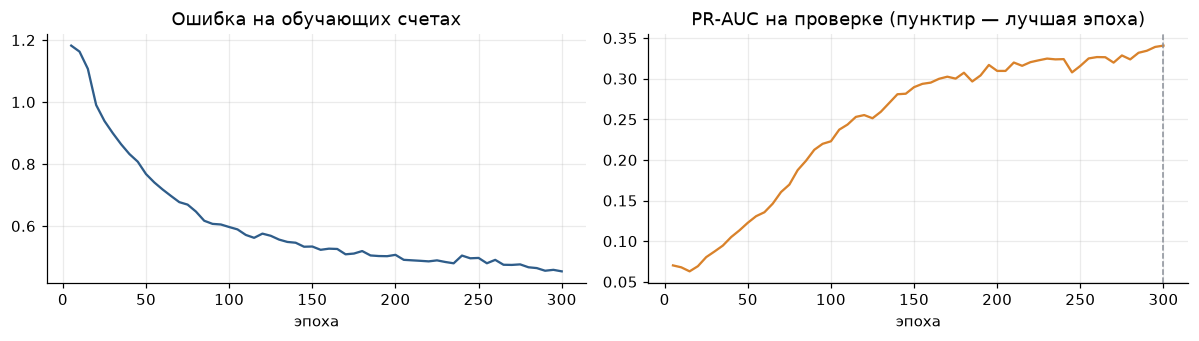

In [30]:
# @title Как шло обучение
c = np.array(curve)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].plot(c[:, 0], c[:, 1], color=BLUE); ax[0].set_title("Ошибка на обучающих счетах"); ax[0].set_xlabel("эпоха")
ax[1].plot(c[:, 0], c[:, 2], color=ORANGE); ax[1].axvline(best_epoch, color=GREY, ls="--", lw=1)
ax[1].set_title("PR-AUC на проверке (пунктир — лучшая эпоха)"); ax[1].set_xlabel("эпоха")
plt.tight_layout(); plt.show()

PR-AUC                   0.375
ROC-AUC                  0.933
полнота при 1% ложных    0.385
точность топ-100         0.890

Решение на пороге (тестовые счета):
порог                  0.954094
поймано дропов              185
пропущено дропов            413
ложных тревог               162
обычных без тревоги       41900


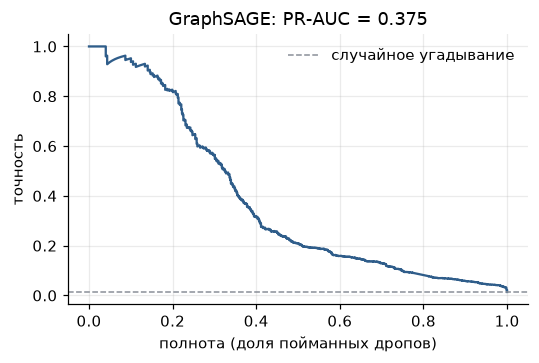

In [31]:
# @title Результат на тесте
report("GraphSAGE", s_sage)

---
## 5. Сравнение моделей

Все модели проверены на **одних и тех же** тестовых счетах. В таблицу попадает последний запуск каждой модели. Если вы поменяли параметры и перезапустили модель, её строка обновится.

In [32]:
# @title Таблица
cols = ["PR-AUC", "ROC-AUC", "полнота при 1% ложных", "точность топ-100",
        "поймано дропов", "пропущено дропов", "ложных тревог"]
table = pd.DataFrame({k: {c: v[c] for c in cols} for k, v in RESULTS.items()}).T
table.style.format({c: "{:.3f}" for c in cols[:4]}).background_gradient(subset=["PR-AUC"], cmap="Blues")

,PR-AUC,ROC-AUC,полнота при 1% ложных,точность топ-100,поймано дропов,пропущено дропов,ложных тревог
Правило,0.033,0.679,0.059,0.100,52.000000,546.000000,753.000000
Логистическая регрессия,0.054,0.799,0.059,0.090,121.000000,477.000000,1338.000000
Бустинг,0.338,0.935,0.318,0.960,159.000000,439.000000,186.000000
GraphSAGE,0.375,0.933,0.385,0.890,185.000000,413.000000,162.000000


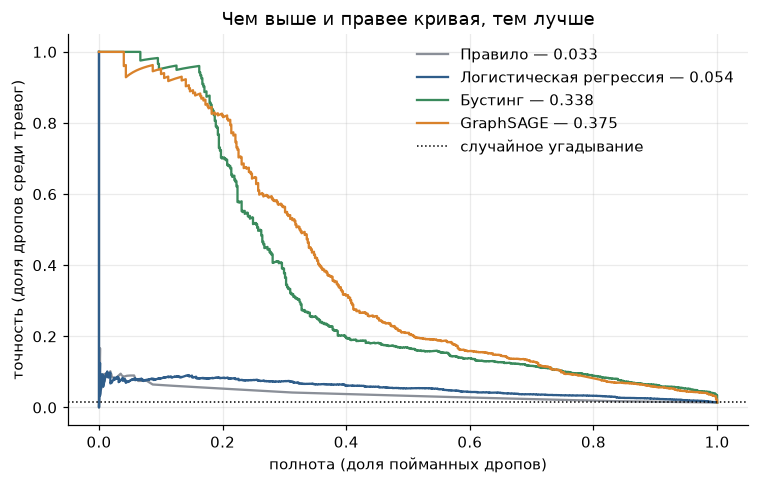

In [33]:
# @title Кривые «точность — полнота» всех моделей
palette = [GREY, BLUE, GREEN, ORANGE, RED, "#6b5b95"]
plt.figure(figsize=(7, 4.5))
for (name, v), col in zip(RESULTS.items(), palette):
    p, r, _ = precision_recall_curve(y[te], v["score"][te])
    plt.plot(r, p, color=col, label=f"{name} — {v['PR-AUC']:.3f}")
plt.axhline(y[te].mean(), color="black", ls=":", lw=1, label="случайное угадывание")
plt.xlabel("полнота (доля пойманных дропов)"); plt.ylabel("точность (доля дропов среди тревог)")
plt.legend(frameon=False); plt.title("Чем выше и правее кривая, тем лучше")
plt.tight_layout(); plt.show()

### Как читать результат

- **Правило и регрессия** лучше случайного угадывания, но сильно отстают: по признакам одного счёта, без соседей, дропа почти не видно.
- **Бустинг** резко лучше — потому что ему дали средние признаки соседей. Выключите `USE_NEIGHBORS` в разделе 3 и перезапустите: так видно, сколько дают соседи.
- **GraphSAGE** сам учится, что брать у соседей и у соседей соседей. Обычно это даёт ещё немного сверху.

На GPU результат GraphSAGE может отличаться от лаборатории в третьем знаке: вычисления на видеокарте идут в другом порядке. На CPU с `SEED = 42` получаются те же цифры, что в лаборатории.

### Что попробовать

1. Регрессия: `CLASS_WEIGHT = "None"` — что стало с полнотой?
2. Бустинг: выключить `USE_NEIGHBORS`; поменять `GB_LEARNING_RATE` на 0.03 и 0.3.
3. GraphSAGE: при `EPOCHS = 300` лучшей оказалась последняя эпоха, то есть сеть ещё не доучилась — попробуйте `EPOCHS = 500`. Ещё: `LAYERS = 1` (только прямые соседи) против `LAYERS = 3`; `HIDDEN = 16` и `128`; `DROPOUT = 0`.
4. Другой `SEED` в разделе 0, затем «Выполнить все»: насколько цифры зависят от случайного разбиения.

### Источники

- Altman E. et al. Realistic Synthetic Financial Transactions for Anti-Money Laundering Models. NeurIPS 2023, Datasets and Benchmarks.
- Hamilton W., Ying R., Leskovec J. Inductive Representation Learning on Large Graphs. NeurIPS 2017.